## Environment setup

In [32]:
from pathlib import Path
import os
import json
import time
import random
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

RANDOM_STATE = 41126

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1
Device: cpu


## Part A - Reproducing and documenting baseline

Dataset

In [33]:
DATA_DIR = next(
    folder for folder in (Path('.'), Path('week8'), Path('kse-github/practicals/week8'))
    if (folder / 'Swissprot_Train_Validation_dataset.csv').exists()
)
TRAIN_VAL_PATH = DATA_DIR / 'Swissprot_Train_Validation_dataset.csv'
HPA_TEST_PATH = DATA_DIR / 'hpa_testset.csv'

swissprot_raw = pd.read_csv(TRAIN_VAL_PATH)
hpa_raw = pd.read_csv(HPA_TEST_PATH)

# Use labels present in both files so the external test has the same target space.
TARGET_COLUMNS = [
    'Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion',
    'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus',
    'Peroxisome',
]

df = swissprot_raw.rename(columns={'ACC': 'protein_id', 'Sequence': 'sequence', 'Partition': 'partition'}).copy()
hpa_df = hpa_raw.rename(columns={'sid': 'protein_id', 'fasta': 'sequence'}).copy()
print('SwissProt:', df.shape, '| HPA:', hpa_df.shape)

SwissProt: (28303, 16) | HPA: (1717, 11)


In [34]:
df

,Unnamed: 0,protein_id,Kingdom,partition,Membrane,Cytoplasm,Nucleus,Extracellular,Cell membrane,Mitochondrion,Plastid,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome,sequence
0,0,Q28165,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
1,1,Q86U42,Metazoa,4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...
2,2,Q0GA42,Metazoa,3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAALGVRLRDCCSRGAVLLLFFSLSPRPPAAAAWLLGLR...
3,3,P82349,Metazoa,1,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATEQQGSNGPVKKSMREKAVERRNVNKEHNSNFKAGY...
4,4,Q7L5N1,Metazoa,1,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MAAAAAAAAATNGTGGSSGMEVDAAVVPSVMACGVTGSVSVALHPL...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28298,28298,Q09712,Fungi,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,MYYIGHPSYYRKHIEHVCFQHSGILKKRNYQKNQKKYIMKLNESAM...
28299,28299,Q9V3C5,Metazoa,2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,MYYPVGWPKRVGLALPGESASIRHICCDAVKILVAAVGDDFLGIWY...
28300,28300,Q9SQQ9,Viridiplantae,4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MYYQNQHQGKNILSSSRMHITSERHPFLRGNSPGDSGLILSTDAKP...
28301,28301,Q9SQQ9-3,Viridiplantae,4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MYYQNQHQGKNILSSSRMHITSERHPFLRGNSPGDSGLILSTDAKP...


Skipping data exploration as dataset is the same as in practical, foundings from there are applicable here.

In [35]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

PAD_TOKEN = "<PAD>" #to unify size
UNK_TOKEN = "<UNK>" #to indicate new

VOCAB = [PAD_TOKEN, UNK_TOKEN] + AMINO_ACIDS

aa_to_idx = {aa: i for i, aa in enumerate(VOCAB)}
idx_to_aa = {i: aa for aa, i in aa_to_idx.items()}

print("Vocabulary size:", len(VOCAB))
print(aa_to_idx)

def encode_sequence(sequence):
    return [
        aa_to_idx.get(aa, aa_to_idx[UNK_TOKEN])
        for aa in sequence
    ]

example_sequence = "MKWVTFISLL"

print(example_sequence)
print(encode_sequence(example_sequence))

MAX_LEN = 400

def encode_and_pad(sequence, max_len=MAX_LEN):
    ids = encode_sequence(sequence)

    ids = ids[:max_len]
    length = len(ids)

    padded = ids + [aa_to_idx[PAD_TOKEN]] * (max_len - length)
    mask = [1] * length + [0] * (max_len - length)

    return (
        torch.tensor(padded, dtype=torch.long),
        torch.tensor(mask, dtype=torch.bool),
        length
    )

ids, mask, length = encode_and_pad(example_sequence)

print(ids.shape)
print(mask.shape)
print("Original length:", length)

class ProteinSequenceDataset(Dataset):
    def __init__(self, dataframe, label_columns, max_len=400):
        self.df = dataframe.reset_index(drop=True)
        self.label_columns = label_columns
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        ids, mask, length = encode_and_pad(row['sequence'], self.max_len)

        # A protein can have several positive localization labels.
        y = torch.tensor(row[self.label_columns].to_numpy(dtype=np.float32))
        return {
            'input_ids': ids,
            'attention_mask': mask,
            'length': length,
            'label': y,
            'protein_id': row['protein_id'],
        }

Vocabulary size: 22
{'<PAD>': 0, '<UNK>': 1, 'A': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7, 'H': 8, 'I': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'P': 14, 'Q': 15, 'R': 16, 'S': 17, 'T': 18, 'V': 19, 'W': 20, 'Y': 21}
MKWVTFISLL
[12, 10, 20, 19, 18, 6, 9, 17, 11, 11]
torch.Size([400])
torch.Size([400])
Original length: 10


In [36]:
# Keep only target columns shared by the two datasets.
MAX_LEN = 400
train_df = df[df['partition'].isin([0, 1, 2, 3])].copy()
val_df = df[df['partition'] == 4].copy()
# A zero here would mean only an excluded localization label was present.
train_df = train_df[train_df[TARGET_COLUMNS].sum(axis=1) > 0].reset_index(drop=True)
val_df = val_df[val_df[TARGET_COLUMNS].sum(axis=1) > 0].reset_index(drop=True)
test_df = hpa_df.reset_index(drop=True)

print('Train:', len(train_df), '| validation:', len(val_df), '| HPA test:', len(test_df))
print('Test labels available:', [c for c in TARGET_COLUMNS if c in test_df.columns])

label_columns = [c for c in TARGET_COLUMNS if c in train_df.columns and c in test_df.columns]

train_ds = ProteinSequenceDataset(train_df, label_columns, MAX_LEN)
val_ds = ProteinSequenceDataset(val_df, label_columns, MAX_LEN)
test_ds = ProteinSequenceDataset(test_df, label_columns, MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)
print('Labels used:', label_columns)

Train: 19708 | validation: 4719 | HPA test: 1717
Test labels available: ['Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion', 'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus', 'Peroxisome']
Labels used: ['Cytoplasm', 'Nucleus', 'Cell membrane', 'Mitochondrion', 'Endoplasmic reticulum', 'Lysosome/Vacuole', 'Golgi apparatus', 'Peroxisome']


### Baseline LSTM

In [37]:
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        n_classes,
        pad_idx=0,
        bidirectional=False,
        num_layers=1,
        dropout=0.0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0
        )

        out_dim = hidden_dim * (2 if bidirectional else 1)

        self.classifier = nn.Linear(out_dim, n_classes)

        self.bidirectional = bidirectional

    def forward(self, input_ids, attention_mask=None):
        x = self.embedding(input_ids)

        _, (h_n, _) = self.lstm(x)

        if self.bidirectional:
            h_last = torch.cat(
                [h_n[-2], h_n[-1]],
                dim=1
            )
        else:
            h_last = h_n[-1]

        return self.classifier(h_last)

In [38]:
def multilabel_metrics(y_true, logits, threshold=0.5):
    # Each output is an independent label probability.
    y_pred = (1 / (1 + np.exp(-logits)) >= threshold).astype(int)
    return {
        'exact_match': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
        'y_true': y_true,
        'y_pred': y_pred,
    }

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, y_true, logits_all = 0.0, [], []

    for batch in loader:
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        y = batch['label'].to(device)
        optimizer.zero_grad()
        logits = model(ids, mask)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        y_true.append(y.detach().cpu().numpy())
        logits_all.append(logits.detach().cpu().numpy())

    metrics = multilabel_metrics(np.vstack(y_true), np.vstack(logits_all))
    metrics['loss'] = total_loss / len(loader.dataset)
    return metrics

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, y_true, logits_all = 0.0, [], []

    for batch in loader:
        ids = batch['input_ids'].to(device)
        mask = batch['attention_mask'].to(device)
        y = batch['label'].to(device)
        logits = model(ids, mask)
        total_loss += criterion(logits, y).item() * y.size(0)
        y_true.append(y.cpu().numpy())
        logits_all.append(logits.cpu().numpy())

    metrics = multilabel_metrics(np.vstack(y_true), np.vstack(logits_all))
    metrics['loss'] = total_loss / len(loader.dataset)
    return metrics

positive = train_df[label_columns].sum().to_numpy()
pos_weight = (len(train_df) - positive) / (positive + 1e-6)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))

def fit_model(model, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(1, epochs + 1):
        train_metrics = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_metrics = evaluate(model, val_loader, criterion, DEVICE)
        history.append({
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'val_loss': val_metrics['loss'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_micro_f1': val_metrics['micro_f1'],
        })
        print(f'{epoch:02d} | train F1={train_metrics["macro_f1"]:.3f} | val F1={val_metrics["macro_f1"]:.3f}')
    return pd.DataFrame(history)

lstm_model = LSTMClassifier(
    vocab_size=len(VOCAB),
    embedding_dim=64,
    hidden_dim=128,
    n_classes=len(label_columns),
    pad_idx=aa_to_idx[PAD_TOKEN],
).to(DEVICE)


history_lstm = fit_model(lstm_model)
test_metrics_lstm = evaluate(lstm_model, test_loader, criterion, DEVICE)

comparison = pd.DataFrame({
    'LSTM': [count_trainable_parameters(lstm_model), test_metrics_lstm['macro_f1']]
}, index=['trainable_parameters', 'HPA_macro_f1']).T
display(comparison)

01 | train F1=0.241 | val F1=0.248
02 | train F1=0.252 | val F1=0.236
03 | train F1=0.239 | val F1=0.244
04 | train F1=0.291 | val F1=0.340
05 | train F1=0.261 | val F1=0.199


,trainable_parameters,HPA_macro_f1
LSTM,101768.0,0.167707


In [39]:
print("val metrics")
print(history_lstm)

val metrics
   epoch  train_loss  val_loss  train_macro_f1  val_macro_f1  val_micro_f1
0      1    1.153223  1.090410        0.241043      0.247981      0.377578
1      2    1.146202  1.092424        0.251692      0.236474      0.272627
2      3    1.141207  1.089536        0.238882      0.243736      0.282549
3      4    1.108174  0.992251        0.290963      0.340457      0.416885
4      5    1.126014  1.106693        0.261374      0.198620      0.213958


In [40]:
print("Exact match:", test_metrics_lstm['exact_match'])
print("Macro f1:", test_metrics_lstm["macro_f1"])
print("Micro f1:", test_metrics_lstm['micro_f1'])

Exact match: 0.0011648223645894002
Macro f1: 0.16770713993690212
Micro f1: 0.2419984387197502


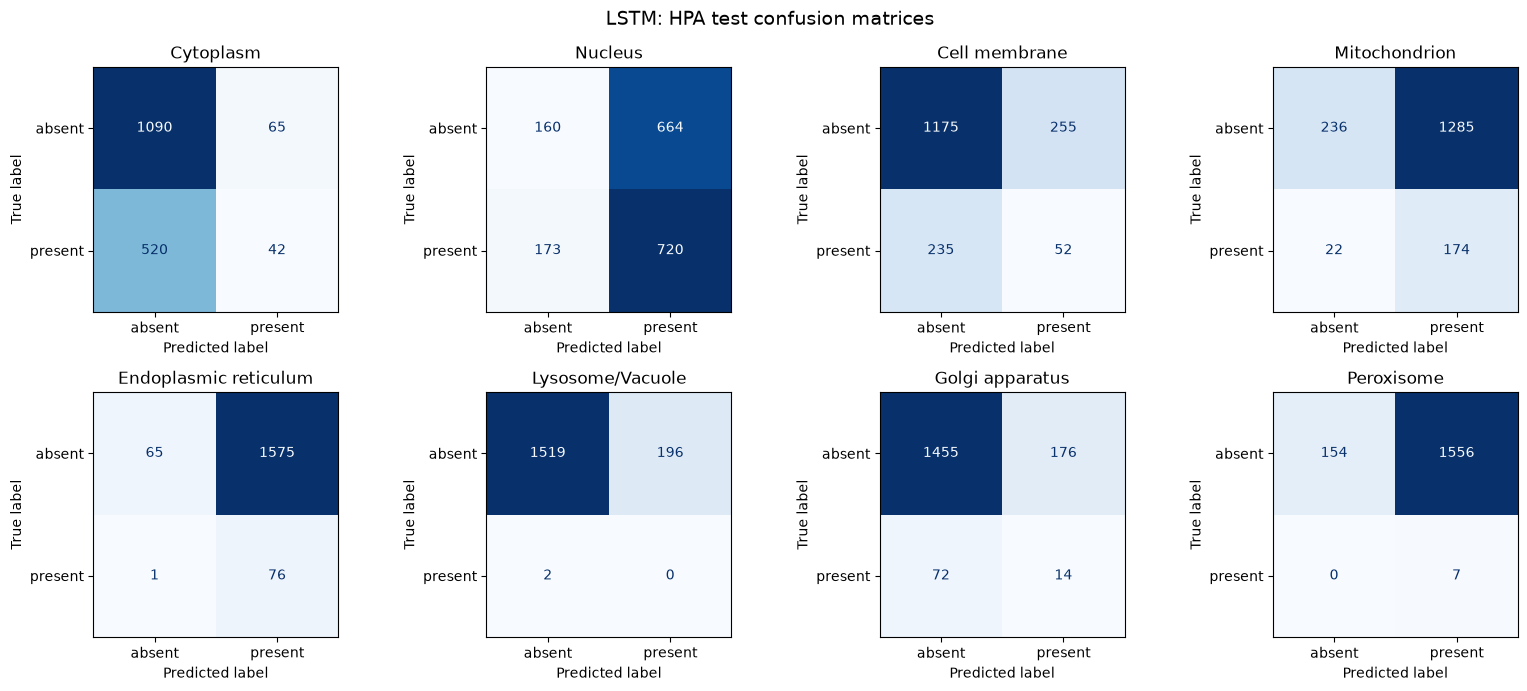

LSTM: macro-F1 = 0.168


,protein_id,true_labels,predicted_labels,highest_probability
0,ENSP00000355743,Nucleus,"Cell membrane, Lysosome/Vacuole, Golgi apparatus",0.615796
1,ENSP00000429628,Nucleus,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
2,ENSP00000266544,Mitochondrion,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.596297
3,ENSP00000470652,Golgi apparatus,Cell membrane,0.577868
4,ENSP00000460751,Nucleus,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
5,ENSP00000485945,Nucleus,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
6,ENSP00000472858,Nucleus,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
7,ENSP00000398124,Nucleus,"Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
8,ENSP00000430889,"Nucleus, Cell membrane","Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016
9,ENSP00000428877,"Nucleus, Cell membrane","Nucleus, Mitochondrion, Endoplasmic reticulum,...",0.594016


In [41]:
from sklearn.metrics import multilabel_confusion_matrix

def collect_logits(model, loader, device):
    model.eval()
    all_true, all_logits = [], []
    with torch.inference_mode():
        for batch in loader:
            inputs = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            all_true.append(batch['label'].cpu().numpy())
            all_logits.append(model(inputs, mask).cpu().numpy())
    return np.vstack(all_true), np.vstack(all_logits)

def plot_multilabel_confusions(y_true, y_pred, model_name):
    matrices = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for label, matrix, ax in zip(label_columns, matrices, axes.ravel()):
        ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=['absent', 'present']
        ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
        ax.set_title(label)
    fig.suptitle(f'{model_name}: HPA test confusion matrices', fontsize=14)
    plt.tight_layout()
    plt.show()

def prediction_table(model, model_name, frame=test_df, loader=test_loader, threshold=0.5):
    y_true, logits = collect_logits(model, loader, DEVICE)
    probabilities = 1 / (1 + np.exp(-logits))
    y_pred = (probabilities >= threshold).astype(int)
    rows = []
    for i in range(len(y_true)):
        true_names = [label for label, value in zip(label_columns, y_true[i]) if value == 1]
        pred_names = [label for label, value in zip(label_columns, y_pred[i]) if value == 1]
        rows.append({
            'protein_id': frame.iloc[i]['protein_id'],
            'true_labels': ', '.join(true_names) or 'none',
            'predicted_labels': ', '.join(pred_names) or 'none',
            'highest_probability': probabilities[i].max(),
        })
    result = pd.DataFrame(rows)
    print(f'{model_name}: macro-F1 = {f1_score(y_true, y_pred, average="macro", zero_division=0):.3f}')
    return result

for model_name, model in [ ('LSTM', lstm_model)]:
    true_labels, model_logits = collect_logits(model, test_loader, DEVICE)
    model_predictions = (1 / (1 + np.exp(-model_logits)) >= 0.5).astype(int)
    plot_multilabel_confusions(true_labels, model_predictions, model_name)
    display(prediction_table(model, model_name).head(10))

### Baseline ESM-2

In [42]:
from transformers import AutoTokenizer, AutoModel

LOCAL_ESM_MODEL = 'facebook/esm2_t6_8M_UR50D'
RUN_LOCAL_ESM = True  # Set True after installing transformers and downloading the checkpoint.

if RUN_LOCAL_ESM:
    esm_tokenizer = AutoTokenizer.from_pretrained(LOCAL_ESM_MODEL)
    esm_model = AutoModel.from_pretrained(LOCAL_ESM_MODEL).to(DEVICE)
    esm_model.eval()
    print('Loaded:', LOCAL_ESM_MODEL)
else:
    print('Local ESM loading is disabled; set RUN_LOCAL_ESM=True to run this section.')

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded: facebook/esm2_t6_8M_UR50D


In [43]:
def masked_mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).type_as(last_hidden_state)

    summed = (last_hidden_state * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)

    return summed / counts

In [44]:
RUN_LOCAL_EMBEDDINGS = True
EMBEDDING_PATH = DATA_DIR / 'esm2_embeddings.parquet'
MAX_LEN = 600
# Recreate this list here so the cell also works after a partial kernel restart.
label_columns = [c for c in TARGET_COLUMNS if c in train_df.columns and c in test_df.columns]

def generate_embeddings(frame, split_name, batch_size=8):
    rows = []
    for start in range(0, len(frame), batch_size):
        batch_frame = frame.iloc[start:start + batch_size]
        encoded = esm_tokenizer(
            batch_frame['sequence'].tolist(),
            truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt'
        )
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
        with torch.no_grad():
            output = esm_model(**encoded)
        pooled = masked_mean_pool(output.last_hidden_state, encoded['attention_mask'])
        for protein_id, vector, (_, row) in zip(batch_frame['protein_id'], pooled.cpu().numpy(), batch_frame.iterrows()):
            rows.append({'protein_id': protein_id, 'split': split_name, **{f'esm_{i}': value for i, value in enumerate(vector)}, **{label: row[label] for label in label_columns}})
    return pd.DataFrame(rows)

if RUN_LOCAL_EMBEDDINGS and RUN_LOCAL_ESM:
    embeddings_df = pd.concat([
        generate_embeddings(train_df, 'train'),
        generate_embeddings(val_df, 'validation'),
        generate_embeddings(test_df, 'hpa_test'),
    ], ignore_index=True)
    embeddings_df.to_parquet(EMBEDDING_PATH, index=False)
    print('Saved:', EMBEDDING_PATH)
elif EMBEDDING_PATH.exists():
    embeddings_df = pd.read_parquet(EMBEDDING_PATH)
    print('Loaded:', EMBEDDING_PATH)
else:
    embeddings_df = None
    print('Embedding generation is disabled and no cached table was found.')

Saved: esm2_embeddings.parquet


In [45]:

feature_cols = [c for c in embeddings_df.columns if c.startswith('esm_')]
emb_train = embeddings_df[embeddings_df['split'] == 'train']
emb_val = embeddings_df[embeddings_df['split'] == 'validation']
emb_test = embeddings_df[embeddings_df['split'] == 'hpa_test']
X_train, X_val, X_test = (emb[feature_cols].to_numpy() for emb in (emb_train, emb_val, emb_test))
y_train, y_val, y_test = (emb[label_columns].to_numpy() for emb in (emb_train, emb_val, emb_test))

linear_probe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight='balanced'))),])
linear_probe.fit(X_train, y_train)
for name, features, labels in [('validation', X_val, y_val), ('HPA test', X_test, y_test)]:
        predictions = linear_probe.predict(features)
        emb_metrics = multilabel_metrics(labels, predictions)
        print(name)
        print("Exact match:", emb_metrics['exact_match'])
        print("Macro f1:", emb_metrics["macro_f1"])
        print("Micro f1:", emb_metrics['micro_f1']) 

validation
Exact match: 0.0
Macro f1: 0.2457079635205649
Micro f1: 0.2721010595693068
HPA test
Exact match: 0.0
Macro f1: 0.23256458657736323
Micro f1: 0.26631326517733184


Linear probe HPA test macro-F1: 0.288


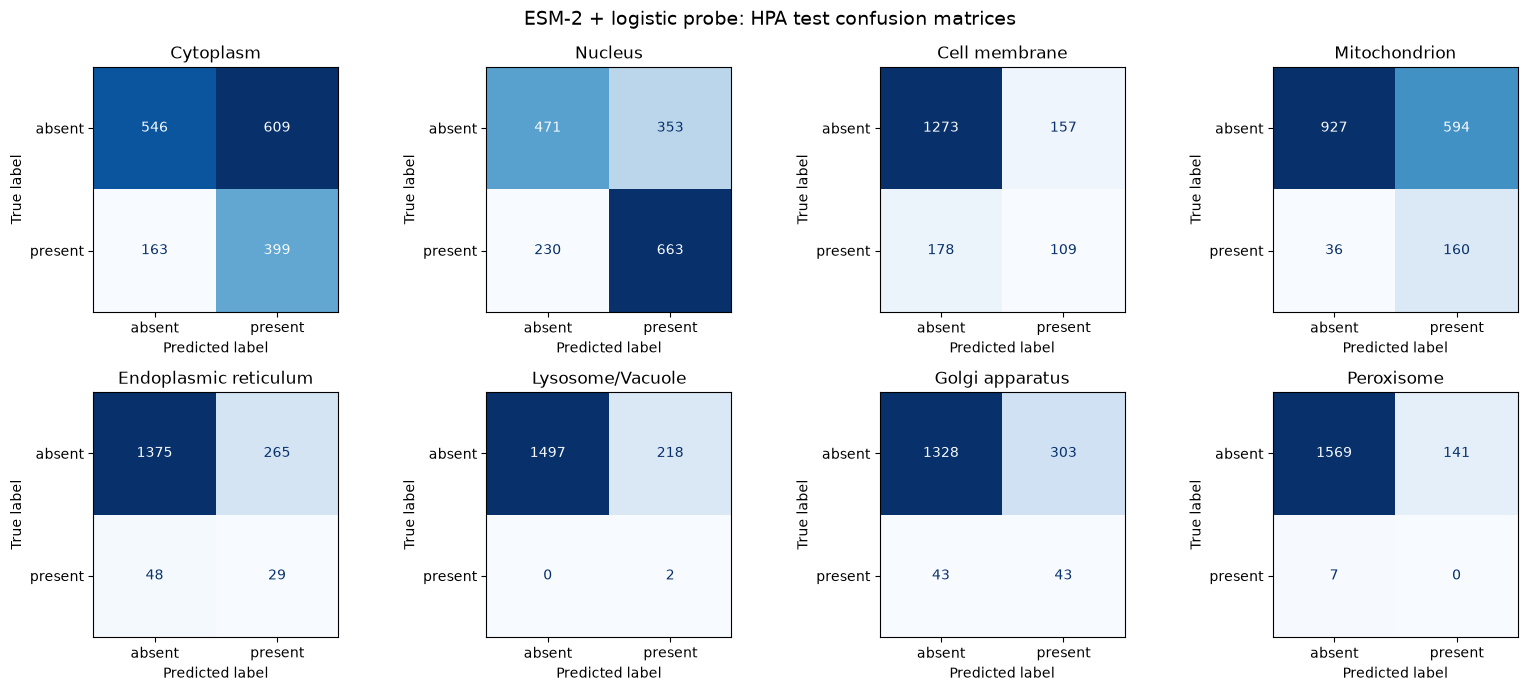

In [46]:

linear_test_predictions = linear_probe.predict(X_test)
print('Linear probe HPA test macro-F1:', round(f1_score(y_test, linear_test_predictions, average='macro', zero_division=0), 3))
plot_multilabel_confusions(y_test, linear_test_predictions, 'ESM-2 + logistic probe')

### Parameters used and results

- random seed: 41126
- maximum sequence length: 400 for LSTM, 600 for ESM-2 + logistic.
- batch size (LSTM only): 64 for train, 128 for val and test
- number of epochs: 5 for LSTM, non-applicable for ESM-2 + logistic.
- decision threshold: standard 0.5

The metrics are reported in output cells for each of the methods

Answers:
- Macro F1 is the best in this case, as it is averaging metrics calculated for each class and this way is not that sensitive to class imbalance. Exact match would be informative only in case the models did great with regard to other metrics, but we can see that it is too strict (requiring all labels to be predicted correctly) and results in low scores at least for baselines.
- For ESM-2 ER Nucleus seems to be the easiest to predict (diagonal is darker than other cells), the other labels (Like ER, Lysosome, etc) seem "easy" but this is mostly because they have few "present" and we can see that actually they are rarely recognized. The hardest one seems to be cytoplasm (the most misses from the actual label).
- Mostly miss, but some false positived present too. 

## Part B — Data-efficiency experiment

Fraction  10% | Proteins:  1971 | Val Macro-F1: 0.2457
--> HPA Test Macro-F1 (100% data): 0.2326
Fraction  25% | Proteins:  4927 | Val Macro-F1: 0.2457
--> HPA Test Macro-F1 (100% data): 0.2326
Fraction  50% | Proteins:  9854 | Val Macro-F1: 0.2457
--> HPA Test Macro-F1 (100% data): 0.2326
Fraction 100% | Proteins: 19708 | Val Macro-F1: 0.2457
--> HPA Test Macro-F1 (100% data): 0.2326


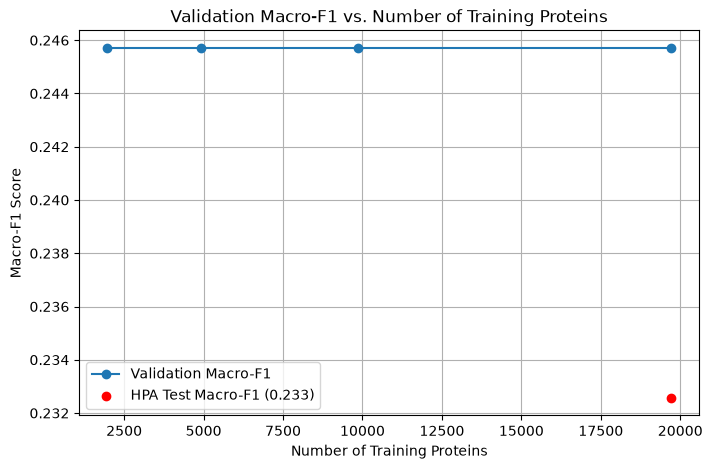

In [50]:
fractions = [0.10, 0.25, 0.50, 1.0]
num_proteins = []
val_macro_f1s = []
test_macro_f1_final = None

for frac in fractions:
    emb_train_frac = emb_train.sample(frac=frac, random_state=RANDOM_STATE)
    n_samples = len(emb_train_frac)
    num_proteins.append(n_samples)
    
    X_train_frac = emb_train_frac[feature_cols].to_numpy()
    y_train_frac = emb_train_frac[label_columns].to_numpy()
    
    probe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight='balanced')))
    ])
    
    probe.fit(X_train_frac, y_train_frac)
    
    val_preds = probe.predict(X_val)
    val_metrics = multilabel_metrics(y_val, val_preds)
    val_macro_f1s.append(val_metrics['macro_f1'])
    
    print(f"Fraction {frac*100:3.0f}% | Proteins: {n_samples:5d} | Val Macro-F1: {val_metrics['macro_f1']:.4f}")
    
    
    test_preds = probe.predict(X_test)
    test_metrics = multilabel_metrics(y_test, test_preds)
    test_macro_f1_final = test_metrics['macro_f1']
    print(f"--> HPA Test Macro-F1 (100% data): {test_macro_f1_final:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(num_proteins, val_macro_f1s, marker='o', label='Validation Macro-F1')
plt.scatter([num_proteins[-1]], [test_macro_f1_final], color='red', zorder=5, 
            label=f'HPA Test Macro-F1 ({test_macro_f1_final:.3f})')

plt.title('Validation Macro-F1 vs. Number of Training Proteins')
plt.xlabel('Number of Training Proteins')
plt.ylabel('Macro-F1 Score')
plt.grid(True)
plt.legend()
plt.show()


--- Training LSTM on  10% of data (1971 proteins) ---
Epoch 01 | train F1=0.234 | val F1=0.228
Epoch 02 | train F1=0.241 | val F1=0.236
Epoch 03 | train F1=0.234 | val F1=0.224
Epoch 04 | train F1=0.209 | val F1=0.197
Epoch 05 | train F1=0.209 | val F1=0.213

--- Training LSTM on  25% of data (4927 proteins) ---
Epoch 01 | train F1=0.170 | val F1=0.205
Epoch 02 | train F1=0.216 | val F1=0.210
Epoch 03 | train F1=0.215 | val F1=0.239
Epoch 04 | train F1=0.224 | val F1=0.224
Epoch 05 | train F1=0.223 | val F1=0.207

--- Training LSTM on  50% of data (9854 proteins) ---
Epoch 01 | train F1=0.215 | val F1=0.238
Epoch 02 | train F1=0.225 | val F1=0.246
Epoch 03 | train F1=0.220 | val F1=0.236
Epoch 04 | train F1=0.218 | val F1=0.248
Epoch 05 | train F1=0.241 | val F1=0.223

--- Training LSTM on 100% of data (19708 proteins) ---
Epoch 01 | train F1=0.236 | val F1=0.246
Epoch 02 | train F1=0.226 | val F1=0.232
Epoch 03 | train F1=0.226 | val F1=0.247
Epoch 04 | train F1=0.228 | val F1=0.247


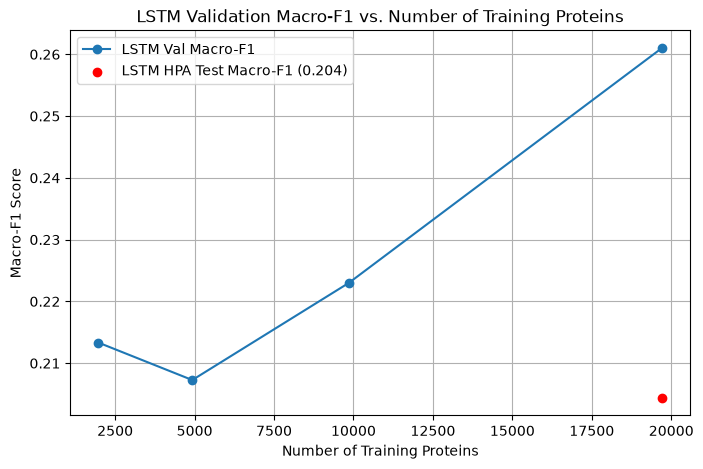

In [49]:

num_proteins_lstm = []
val_macro_f1s_lstm = []
test_macro_f1_final_lstm = None

def fit_model_subset(model, subset_train_loader, subset_criterion, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for epoch in range(1, epochs + 1):
        train_metrics = train_epoch(model, subset_train_loader, subset_criterion, optimizer, DEVICE)
        val_metrics = evaluate(model, val_loader, subset_criterion, DEVICE)
        history.append({
            'epoch': epoch,
            'val_macro_f1': val_metrics['macro_f1']
        })
        print(f'Epoch {epoch:02d} | train F1={train_metrics["macro_f1"]:.3f} | val F1={val_metrics["macro_f1"]:.3f}')
    return history

for frac in fractions:
    train_df_frac = train_df.sample(frac=frac, random_state=RANDOM_STATE)
    n_samples = len(train_df_frac)
    num_proteins_lstm.append(n_samples)
    
    print(f"\n--- Training LSTM on {frac*100:3.0f}% of data ({n_samples} proteins) ---")
    
    positive = train_df_frac[label_columns].sum().to_numpy()
    pos_weight = (len(train_df_frac) - positive) / (positive + 1e-6)
    criterion_frac = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
    
    train_ds_frac = ProteinSequenceDataset(train_df_frac, label_columns, MAX_LEN)
    train_loader_frac = DataLoader(train_ds_frac, batch_size=64, shuffle=True)
    
    model_frac = LSTMClassifier(
        vocab_size=len(VOCAB),
        embedding_dim=64,
        hidden_dim=128,
        n_classes=len(label_columns),
        pad_idx=aa_to_idx[PAD_TOKEN],
    ).to(DEVICE)
    
    history = fit_model_subset(model_frac, train_loader_frac, criterion_frac, epochs=5)
    
    final_val_f1 = history[-1]['val_macro_f1']
    val_macro_f1s_lstm.append(final_val_f1)
    
    if frac == 1.0:
        test_metrics = evaluate(model_frac, test_loader, criterion_frac, DEVICE)
        test_macro_f1_final_lstm = test_metrics['macro_f1']
        print(f"\n--> LSTM HPA Test Macro-F1 (100% data): {test_macro_f1_final_lstm:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(num_proteins_lstm, val_macro_f1s_lstm, marker='o', label='LSTM Val Macro-F1')
plt.scatter([num_proteins_lstm[-1]], [test_macro_f1_final_lstm], color='red', zorder=5, 
            label=f'LSTM HPA Test Macro-F1 ({test_macro_f1_final_lstm:.3f})')

plt.title('LSTM Validation Macro-F1 vs. Number of Training Proteins')
plt.xlabel('Number of Training Proteins')
plt.ylabel('Macro-F1 Score')
plt.grid(True)
plt.legend()
plt.show()

Answers:
- As we can see the ESM-2+logistic result doesn't change with different amount of data used for training. This happens because we use pretrained embeddings and only fit logistic model additionally, performance of which doesn't change much if more data is added (as already on 10% we have enough, almost 2 thousands). For LSTM we can see that validation macro F1 score is growing with growing amount of data up untill the point where the whole dataset is used.
- If we're talking about ESM-2+logistic yes, because the model basically is the same.
- For pretrained model + logistic regression it is expected that there is not muh sense in adding new data. For LSTM we see the difference and that best performance is on the full data.

## Part C - Frozen versus fine-tuned ESM-2

For this task I've ran provided `train_esm.py` with commands from instructions to GPU server `.md` file. For LoRA separate script was used `train_esm_with_lora.py` (only flag for using LoRA added, but didn't want to cause conflicts). 

| Model | Training mode | Trainable parameters | Max length | Batch size | Val macro-F1 | HPA macro-F1 | Time/epoch | Peak GPU memory |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| LSTM or BiLSTM | from scratch | 101,768 | 400 | 64 | 0.261 | 0.2044 | 43.68 s | Not applicable (ran on cpu)|
| ESM-2 8M + logistic probe | frozen embeddings | 2568 (counted manually as 320 weights + 1 bias per class * 8 for number of classes) | 600 | Not applicable | 0.2457 | 0.2326 | Not applicable | Not applicable (ran on cpu) |
| ESM-2 35M + head | frozen | 3,848 | 400 | 8 | 0.42797 | 0.30219 | 99.3 s | 841MiB |
| ESM-2 35M | partial | 5,545,928 | 400 | 4 | 0.476 | 0.48981 | 150.74 s | 983MiB |
| ESM-2 35M | full | 33,504,249 | 400 | 2 | 0.5122 | 0.318 | 417,08 s | 1555MiB |
| ESM-2 35M | LoRA | 280,328 | 400 | 8 | 0.48955 | 0.34675| 162,012 s | 2465 MiB |

Answers:
- Yes, quite significantly
- Partial finetuning, the other 2 finetuning methods improved validation but reduced HPA scores
- To see what classes are better with finetuned model I used `export_per_class.py` on fully finetuned (best val score) model, on server, to export f1 per class.

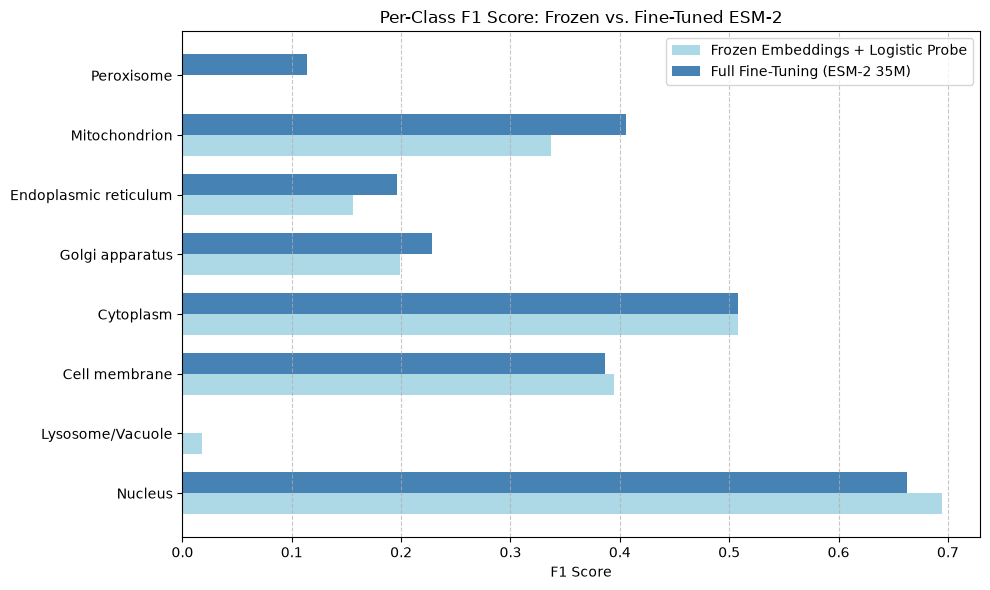

,Label,Logistic_F1,Finetuned_F1,Improvement
7,Peroxisome,0.000000,0.114286,0.114286
3,Mitochondrion,0.336842,0.405926,0.069084
4,Endoplasmic reticulum,0.156334,0.195918,0.039584
6,Golgi apparatus,0.199074,0.228261,0.029187
0,Cytoplasm,0.508280,0.508501,0.000221
2,Cell membrane,0.394213,0.386412,-0.007801
5,Lysosome/Vacuole,0.018018,0.000000,-0.018018
1,Nucleus,0.694605,0.662187,-0.032418


In [52]:
logistic_preds = linear_probe.predict(X_test)
logistic_f1 = f1_score(y_test, logistic_preds, average=None, zero_division=0)

local_df = pd.DataFrame({
    'Label': label_columns,
    'Logistic_F1': logistic_f1
})

server_df = pd.read_csv("outputs/finetuned_per_class_f1.csv")

comparison_df = pd.merge(local_df, server_df, on='Label')
comparison_df['Improvement'] = comparison_df['Finetuned_F1'] - comparison_df['Logistic_F1']
comparison_df = comparison_df.sort_values('Improvement', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(comparison_df))
height = 0.35

ax.barh(y - height/2, comparison_df['Logistic_F1'], height, label='Frozen Embeddings + Logistic Probe', color='lightblue')
ax.barh(y + height/2, comparison_df['Finetuned_F1'], height, label='Full Fine-Tuning (ESM-2 35M)', color='steelblue')

ax.set_yticks(y)
ax.set_yticklabels(comparison_df['Label'])
ax.set_xlabel('F1 Score')
ax.set_title('Per-Class F1 Score: Frozen vs. Fine-Tuned ESM-2')
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

display(comparison_df.sort_values('Improvement', ascending=False))

So, according to per-class f1 score, finetuning helped for peroxisome, but reduced or remained similar score for others.

- For all finetunings the validation loss firstly decreases and then increases (after epoch 3 or 4).

## Part D - Threshold and error analysis

For the best scoring on validation model (full finetuning) I performed threshold search (also on the server with `threshold_tunning.py`), therefore resulting files are simply displayed here. 

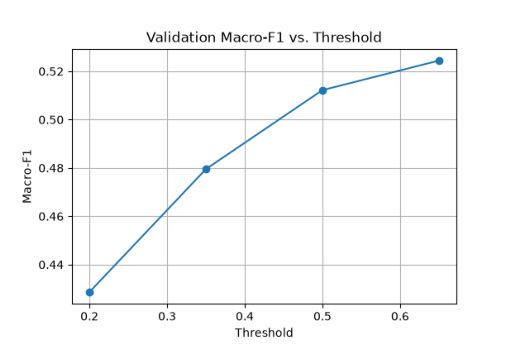

In [53]:
import matplotlib.image as mpimg

img = mpimg.imread('outputs/outputs/esm35m_full/val_macro_f1_vs_threshold.png')
plt.imshow(img)
plt.axis('off')
plt.show()

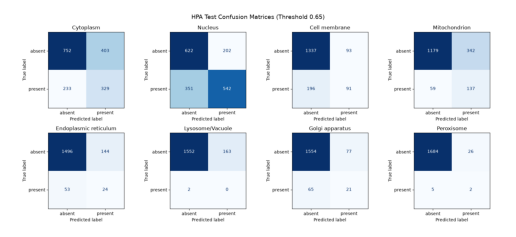

In [ ]:
# Look on the referenced file directly for better visibility
img = mpimg.imread('outputs/outputs/esm35m_full/hpa_test_confusion_matrices.png')
plt.imshow(img)
plt.axis('off')
plt.show()

In [55]:
df = pd.read_csv('outputs/outputs/esm35m_full/prediction_sample.csv')

display(df)

,protein_id,true_labels,predicted_labels,highest_probability
0,ENSP00000355743,Nucleus,Nucleus,0.9358
1,ENSP00000429628,Nucleus,Nucleus,0.9263
2,ENSP00000266544,Mitochondrion,Mitochondrion,0.9936
3,ENSP00000470652,Golgi apparatus,"Endoplasmic reticulum, Golgi apparatus",0.9838
4,ENSP00000460751,Nucleus,"Nucleus, Mitochondrion",0.8786
5,ENSP00000485945,Nucleus,"Mitochondrion, Endoplasmic reticulum",0.8116
6,ENSP00000472858,Nucleus,Mitochondrion,0.9635
7,ENSP00000398124,Nucleus,"Cytoplasm, Nucleus",0.9061
8,ENSP00000430889,"Nucleus, Cell membrane",none,0.6046
9,ENSP00000428877,"Nucleus, Cell membrane",Nucleus,0.9406


Here we can see in row 3 false positive prediction for ER, which is reasonable as Proteins for Golgi should go through secretory pathway (in most cases) and therefore in ER as well, which model likely learned. In row 6 we can see false negative (Mitochondrion indtead of nucleous), maybe this protein has some features that act on DNA, and therefore the model got confused.

Answers:
- As we can see with threshold 0.65 we get better results in general (better macro f1), therefore 0.5 is not reasonable for every Localization or even for the most of localizations.
- For now we can see that 0.65 improved results overall, but I can hypothesise that for low abundance localization lower threshold would bring less false negatives, and the other way around for localizations that have enough representation in the training data.
- For example with ER and Golgi, these localizations will have similar proteins but ER is also mentioned more often in the data, so sometimes simply guessing it for Golgi cases is better for model to keep up its metrics 

In [60]:
from sklearn.model_selection import train_test_split
emb_full = pd.concat([emb_train, emb_val], ignore_index=True)
emb_train_rand, emb_val_rand = train_test_split(emb_full, test_size=len(emb_val), random_state=RANDOM_STATE)

prevalence_original_val = emb_val[label_columns].mean() * 100
prevalence_random_val = emb_val_rand[label_columns].mean() * 100

prevalence_df = pd.DataFrame({
    'Original_Val (%)': prevalence_original_val,
    'Random_Val (%)': prevalence_random_val,
    'Absolute_Difference': abs(prevalence_random_val - prevalence_original_val)
})
display(prevalence_df.sort_values('Absolute_Difference', ascending=False))

X_train_rand = emb_train_rand[feature_cols].to_numpy()
y_train_rand = emb_train_rand[label_columns].to_numpy()
X_val_rand = emb_val_rand[feature_cols].to_numpy()
y_val_rand = emb_val_rand[label_columns].to_numpy()

random_probe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight='balanced')))
])

random_probe.fit(X_train_rand, y_train_rand)

val_preds_rand = random_probe.predict(X_val_rand)
val_metrics_rand = multilabel_metrics(y_val_rand, val_preds_rand)

print("Original Validation Macro-F1:", multilabel_metrics(y_val, linear_probe.predict(X_val))["macro_f1"])
print("Random Validation Macro-F1:  ", val_metrics_rand["macro_f1"])

,Original_Val (%),Random_Val (%),Absolute_Difference
Nucleus,42.742106,39.372748,3.369358
Cell membrane,14.770078,18.097054,3.326976
Golgi apparatus,4.068659,5.085823,1.017165
Lysosome/Vacuole,5.149396,6.124179,0.974783
Endoplasmic reticulum,8.391608,9.281627,0.890019
Cytoplasm,38.800593,39.287985,0.487391
Mitochondrion,10.934520,10.849756,0.084764
Peroxisome,1.123119,1.101928,0.021191


Original Validation Macro-F1: 0.2457079635205649
Random Validation Macro-F1:   0.2544040687073359


Answers:
- The validation score increased by around 0.01
- The most changed are Nucleus and Cell membrane
- The random split wil leak similar proteins or proteins of one group from train to val and therefore be overly optimistic, doesn't show performance on really new proteins. Our first split is also not completely homology aware, but at least doesn't split one partition between train and val which lowers chances of leakage.

Final note: t-SNE/embedding plots or EDA were presented on practical, and therefore weren't carried over here to avoid redundancy. All training results for gpu-side, as well as training history and configs can be found in outputs folder.